# The Diagnostics Playbook (Manual de Diagnóstico)

*Complemento de* **Mastering CatBoost — Pro Edition**, Capítulo 4: Tuning & Diagnostics as System Control, §4.5 (Diagnostics: Reading the Heartbeat), §4.6 (Interpretability: The Ladder of Truth) e §4.8 (The Cookbook).

Este é o fluxo de trabalho sistemático de depuração de modelos do Capítulo 4, estruturado como um procedimento repetível: **auditoria de dados → baseline → testes de vazamento (leakage) → fatiamento de erros (error slicing) → decisão**. Para garantir que cada verificação seja acionada de forma visível, construímos um conjunto de dados deliberadamente com armadilhas contendo as duas patologias de produção mais comuns — uma variável de proxy com vazamento (*leaky proxy feature*) e uma coluna de identificador com alta cardinalidade (*ID-style column*) — além de desbalanceamento de classes, valores ausentes e um segmento fraco. Seu trabalho em projetos reais é executar essa mesma sequência em dados cujas armadilhas você *não* conhece antecipadamente.

In [12]:
# %pip install -q catboost==1.2.10 scikit-learn==1.6.1 numpy==2.0.2 pandas==2.2.2 matplotlib==3.10.0

import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier, Pool

import seaborn as sns

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

sns.set()

## 0. O conjunto de dados com armadilhas (booby-trapped dataset)

Verdade fundamental (*ground truth*, conhecida por nós, oculta do fluxo de trabalho):

- 8 variáveis numéricas legítimas carregam o sinal real; a taxa de positivos é de ~15% (desbalanceamento, Cenário 3 do Cookbook).
- `leaky_score` é um proxy pós-desfecho: essencialmente a variável-alvo mais ruído (pense no "status de pagamento" vazando para um modelo de inadimplência).
- `customer_id` possui ~1 linha por nível — puro combustível para memorização (Cenário 1 do Cookbook).
- `segment` ∈ {A, B, C}: no segmento C o sinal é reduzido pela metade e mais ruidoso (a fatia fraca para análise de fatiamento de erros).
- ~8% de valores ausentes em duas colunas numéricas.

In [2]:
from sklearn.datasets import make_classification
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss
from sklearn.model_selection import train_test_split

n = 15_000
rng = np.random.RandomState(RANDOM_SEED)

X_num, y = make_classification(n_samples=n, n_features=8, n_informative=6, n_redundant=1,
                               weights=[0.85], flip_y=0.06, random_state=RANDOM_SEED)
df = pd.DataFrame(X_num, columns=[f"f{i}" for i in range(8)])

# O segmento C possui ruído extra nos rótulos; isso altera o sinal atingível.
segment = rng.choice(list("ABC"), size=n, p=[0.4, 0.4, 0.2])
seg_c = segment == "C"
flip = seg_c & (rng.rand(n) < 0.15)
y = np.where(flip, 1 - y, y)

df["segment"] = segment
df["leaky_score"] = y * 0.8 + rng.normal(0, 0.35, n)          # proxy pós-desfecho (vazamento de dados)
df["customer_id"] = (rng.permutation(n) // 1.2).astype(int).astype(str)  # ~1 linha por nível (alta cardinalidade / ID)
df.loc[rng.rand(n) < 0.08, "f2"] = np.nan
df.loc[rng.rand(n) < 0.08, "f5"] = np.nan
df["y"] = y

train_df, valid_df = train_test_split(df, test_size=0.3, random_state=RANDOM_SEED, stratify=df["y"])
train_df, valid_df = train_df.reset_index(drop=True), valid_df.reset_index(drop=True)
FEATURES = [c for c in df.columns if c != "y"]
CATS = ["segment", "customer_id"]
print(train_df.shape, valid_df.shape, "| positive rate:", round(df.y.mean(), 3))

(10500, 12) (4500, 12) | positive rate: 0.187


## Passo 1 — Auditoria de dados (Nível 0 da Hierarquia, §4.2.1)

Antes de qualquer modelo: tipos, valores ausentes, cardinalidade, equilíbrio da variável-alvo, duplicatas. O papel da auditoria é identificar *violações de contrato* — problemas que nenhum ajuste de hiperparâmetros consegue corrigir. Dois alertas fundamentais para memorizar:

1. Uma variável categórica com cardinalidade ≈ número de linhas é um ID, não uma feature.
2. Qualquer feature cujo significado só é conhecido *após* o desfecho (pergunta da auditoria: "esse valor existiria no momento da predição?").

In [3]:
audit = pd.DataFrame({
    "dtype": train_df[FEATURES].dtypes.astype(str),
    "n_missing": train_df[FEATURES].isna().sum(),
    "pct_missing": (train_df[FEATURES].isna().mean() * 100).round(1),
    "n_unique": train_df[FEATURES].nunique(),
})
audit["cardinality_ratio"] = (audit["n_unique"] / len(train_df)).round(3)
print(audit)
print(f"\ntarget balance : {train_df.y.mean():.3f} positive (imbalanced -> Scenario 3 applies)")
print(f"duplicated rows: {train_df.duplicated().sum()}")
print(f"train/valid target rates: {train_df.y.mean():.3f} / {valid_df.y.mean():.3f}")

flagged_ids = audit.index[(audit["cardinality_ratio"] > 0.5) & (audit["dtype"] == "object")].tolist()
print(f"\nAUDIT FLAG — ID-like categorical(s): {flagged_ids}")
print("AUDIT QUESTION — for every feature: is it available BEFORE the outcome? "
      "('leaky_score' needs a domain answer; the model will give us a statistical one next.)")

               dtype  n_missing  pct_missing  n_unique  cardinality_ratio
f0           float64          0          0.0     10500              1.000
f1           float64          0          0.0     10500              1.000
f2           float64        832          7.9      9668              0.921
f3           float64          0          0.0     10500              1.000
f4           float64          0          0.0     10500              1.000
f5           float64        849          8.1      9651              0.919
f6           float64          0          0.0     10500              1.000
f7           float64          0          0.0     10500              1.000
segment          str          0          0.0         3              0.000
leaky_score  float64          0          0.0     10500              1.000
customer_id      str          0          0.0      9282              0.884

target balance : 0.187 positive (imbalanced -> Scenario 3 applies)
duplicated rows: 0
train/valid target rates:

## Passo 2 — Baseline

Comece com o tratamento nativo de variáveis categóricas, um teto generoso de iterações e parada antecipada (*early stopping*) baseada em validação. O desbalanceamento de classes por si só não justifica a ponderação automática de classes (*class weighting*): a ponderação altera o objetivo do treinamento e a escala de probabilidades. Comece sem ponderação e, depois, compare a ponderação apenas em relação à métrica de produção/implantação, calibração, ponto de corte (*threshold*) e custo de decisão. O modelo baseline com todas as features permanece um instrumento diagnóstico, não um candidato para produção.

In [4]:
def make_pools(feats):
    cats = [c for c in CATS if c in feats]
    return (Pool(train_df[feats], train_df["y"], cat_features=cats),
            Pool(valid_df[feats], valid_df["y"], cat_features=cats))

def fit_report(feats, name, **extra):
    tr_pool, va_pool = make_pools(feats)
    params = dict(iterations=800, learning_rate=0.05, depth=6, l2_leaf_reg=3,
                  eval_metric="AUC",
                  random_seed=RANDOM_SEED, verbose=0, allow_writing_files=False)
    params.update(extra)
    m = CatBoostClassifier(**params)
    m.fit(tr_pool, eval_set=va_pool, early_stopping_rounds=60, use_best_model=True)
    p_tr = m.predict_proba(train_df[feats])[:, 1]
    p_va = m.predict_proba(valid_df[feats])[:, 1]
    rep = {"model": name,
           "train_AUC": round(roc_auc_score(train_df.y, p_tr), 4),
           "valid_AUC": round(roc_auc_score(valid_df.y, p_va), 4),
           "valid_PR_AUC": round(average_precision_score(valid_df.y, p_va), 4),
           "trees": m.tree_count_}
    rep["gap"] = round(rep["train_AUC"] - rep["valid_AUC"], 4)
    return m, rep

reports = []
m_base, rep = fit_report(FEATURES, "baseline (all features)")
reports.append(rep)
pd.DataFrame(reports)

,model,train_AUC,valid_AUC,valid_PR_AUC,trees,gap
0,baseline (all features),0.994,0.9777,0.9278,499,0.0163


Um AUC de validação suspeitamente alto é, por si só, um sintoma — a assinatura do Cenário 1 é "score de treino 0.99", mas um *vazamento que sobrevive à divisão dos dados* (como o nosso proxy) inflaciona a validação também. É por isso que o próximo passo interroga o modelo em vez de simplesmente confiar no score.

## Passo 3 — Verificações de vazamento / Leakage checks (§4.5.2 + Ladder of Truth, §4.6)

Três sondagens, em ordem crescente de custo:

1. **Dominância de importância** (Degrau 1, `PredictionValuesChange`): o teste de dominação CTR do livro — qualquer feature com mais de ~50% de participação é suspeita.
2. **Formato da curva**: uma curva de validação que salta quase imediatamente para o seu teto indica que o modelo encontrou um atalho, não uma estrutura real.
3. **Ablação** (lógica do Degrau 2): remova a suspeita, retreine e observe a métrica. Uma feature *legítima e importante* sobrevive à ablação com uma queda modesta; um *vazamento* leva o seu "milagre" junto consigo.

In [5]:
imp = m_base.get_feature_importance(type="PredictionValuesChange", prettified=True)
imp["share_%"] = (imp["Importances"] / imp["Importances"].sum() * 100).round(1)
print(imp.to_string(index=False))

dominant = imp.loc[imp["share_%"] > 50, "Feature Id"].tolist()
print(f"\nREVIEW CUE — importance share > 50%: "
      f"{dominant if dominant else 'none'}")

curve = m_base.get_evals_result()["validation"]["AUC"]
frac_at_10 = curve[min(9, len(curve)-1)] / max(curve)
print(f"validation AUC after 10 trees = {100*frac_at_10:.1f}% of its maximum "
      "(an early concentration is a review cue, not proof of leakage)")

 Feature Id  Importances  share_%
leaky_score    32.775679     32.8
         f2    13.276405     13.3
         f3     9.683763      9.7
         f1     8.714226      8.7
         f4     8.158418      8.2
         f5     7.903795      7.9
         f7     6.091820      6.1
         f6     5.920675      5.9
         f0     4.090810      4.1
    segment     3.381721      3.4
customer_id     0.002687      0.0

REVIEW CUE — importance share > 50%: none
validation AUC after 10 trees = 98.4% of its maximum (an early concentration is a review cue, not proof of leakage)


In [6]:
# Sonda 3: ablação do principal suspeito
suspects = dominant if dominant else [imp.iloc[0]["Feature Id"]]
feats_clean = [f for f in FEATURES if f not in suspects]
m_clean, rep = fit_report(feats_clean, f"without {suspects}")
reports.append(rep)
pd.DataFrame(reports)

,model,train_AUC,valid_AUC,valid_PR_AUC,trees,gap
0,baseline (all features),0.9940,0.9777,0.9278,499,0.0163
1,without ['leaky_score'],0.9486,0.8850,0.7430,481,0.0636


A ablação mede a dependência do desempenho de validação em relação a uma feature; ela não determina se a feature é legítima ou se estará disponível no momento da decisão. Aqui, a proveniência do domínio informa que `leaky_score` é pós-desfecho, logo deve ser removida independentemente da sua participação na importância ou do impacto da ablação.

### A coluna de ID

`customer_id` é quase única e não tem papel declarado de generalização no momento de inferência/serviço nesta estrutura. Removê-la é o controle limpo. `max_ctr_complexity=1` altera a construção de interações, mas não torna um identificador legítimo nem impede toda a memorização. Mantenha um identificador apenas se o alvo de produção incluir entidades recorrentes e a validação nas futuras entidades pretendidas demonstrar valor legítimo.

In [7]:
feats_no_leak = [f for f in FEATURES if f != "leaky_score"]
feats_no_id = [f for f in feats_no_leak if f != "customer_id"]

_, rep = fit_report(feats_no_leak, "no leak, with customer_id")
reports.append(rep)
_, rep = fit_report(feats_no_leak, "no leak, id throttled (max_ctr_complexity=1)",
                    max_ctr_complexity=1)
reports.append(rep)
m_final, rep = fit_report(feats_no_id, "no leak, id dropped")
reports.append(rep)
pd.DataFrame(reports)

,model,train_AUC,valid_AUC,valid_PR_AUC,trees,gap
0,baseline (all features),0.9940,0.9777,0.9278,499,0.0163
1,without ['leaky_score'],0.9486,0.8850,0.7430,481,0.0636
2,"no leak, with customer_id",0.9486,0.8850,0.7430,481,0.0636
3,"no leak, id throttled (max_ctr_complexity=1)",0.9416,0.8839,0.7358,366,0.0577
4,"no leak, id dropped",0.9302,0.8824,0.7394,321,0.0478


Compare as linhas com ID mantido, limitado (*throttled*) e removido usando a utilidade de validação e o objetivo pretendido em produção. Neste gerador, o ID não carrega sinal algum, mas a cardinalidade por si só não prova que um identificador seja inútil para todo problema com entidades recorrentes. Limitar a complexidade (*throttling*) é um experimento de capacidade do modelo, não um remédio para vazamento.

## Passo 4 — Fatiamento de erros (Error slicing)

Fatie o desempenho de validação por grupos relevantes e faixas de predição. Trate estimativas em fatias pequenas com incerteza.

segment    n  pos_rate    AUC  logloss
      A 1809     0.163 0.8932   0.2516
      B 1798     0.173 0.9095   0.2473
      C  893     0.264 0.7288   0.4796

SLICING FLAG — weakest segment: C (smaller AUC and higher logloss than siblings)


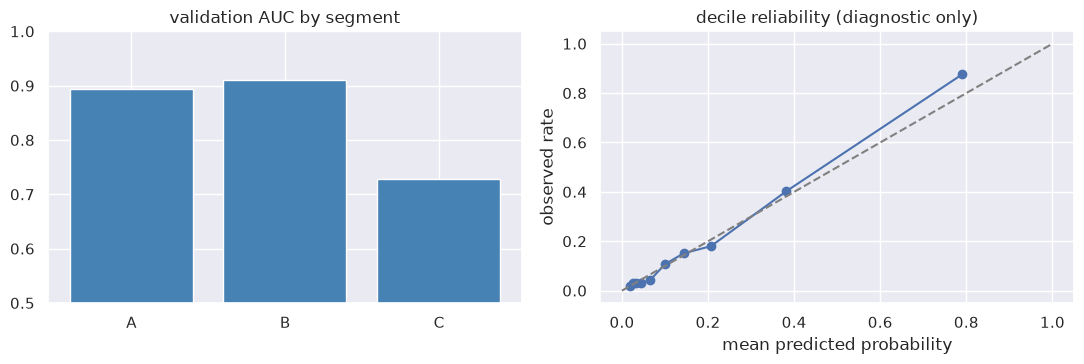

In [13]:
p_va = m_final.predict_proba(valid_df[feats_no_id])[:, 1]
slices = []
for seg, grp_idx in valid_df.groupby("segment").groups.items():
    yy = valid_df.loc[grp_idx, "y"]
    pp = pd.Series(p_va, index=valid_df.index).loc[grp_idx]
    slices.append({"segment": seg, "n": len(yy),
                   "pos_rate": round(yy.mean(), 3),
                   "AUC": round(roc_auc_score(yy, pp), 4),
                   "logloss": round(log_loss(yy, pp, labels=[0, 1]), 4)})
slice_table = pd.DataFrame(slices)
print(slice_table.to_string(index=False))

worst = slice_table.loc[slice_table["AUC"].idxmin(), "segment"]
print(f"\nSLICING FLAG — weakest segment: {worst} "
      "(smaller AUC and higher logloss than siblings)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(slice_table["segment"], slice_table["AUC"], color="steelblue")
axes[0].set_title("validation AUC by segment"); axes[0].set_ylim(0.5, 1.0)

deciles = pd.qcut(p_va, 10, labels=False, duplicates="drop")
dec = pd.DataFrame({"decile": deciles, "pred": p_va, "actual": valid_df["y"].to_numpy()}).groupby("decile").mean()
axes[1].plot(dec["pred"], dec["actual"], "o-")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_xlabel("mean predicted probability"); axes[1].set_ylabel("observed rate")
axes[1].set_title("decile reliability (diagnostic only)")
plt.tight_layout(); plt.show()

Dois achados independentes para registrar:

1. Inspecione a tabela de fatiamento real e seus tamanhos amostrais. O segmento C foi gerado com inversões extras de rótulos, mas uma investigação real não saberia a causa com antecedência; ações candidatas exigem análise de proveniência, incerteza e validação.
2. `m_final` não possui ponderação de classes. Sua curva de confiabilidade (*reliability curve*) é, portanto, uma evidência descritiva desta partição e não pode ser atribuída ao `auto_class_weights`. Se probabilidades calibradas importarem, avalie uma métrica própria e a confiabilidade em dados dedicados; calibre somente após congelar o modelo candidato.

## Passo 5 — Decisão

O playbook é concluído com uma decisão explícita e registrada.

In [9]:
ledger = pd.DataFrame(reports)
ledger

,model,train_AUC,valid_AUC,valid_PR_AUC,trees,gap
0,baseline (all features),0.9940,0.9777,0.9278,499,0.0163
1,without ['leaky_score'],0.9486,0.8850,0.7430,481,0.0636
2,"no leak, with customer_id",0.9486,0.8850,0.7430,481,0.0636
3,"no leak, id throttled (max_ctr_complexity=1)",0.9416,0.8839,0.7358,366,0.0577
4,"no leak, id dropped",0.9302,0.8824,0.7394,321,0.0478


**Modelo de decisão (preencher a partir de evidências e proveniência):**

| Item | Evidência | Ação governada |
|---|---|---|
| campo pós-desfecho | disponibilidade/proveniência mais ablação | remover antes da modelagem |
| ID quase único | estimando de produção e validação sensível a grupos | descartar por padrão; reter somente com contrato legítimo de entidades recorrentes |
| desbalanceamento | prevalência, calibração, custos, métricas de corte | comparar objetivos não ponderados/ponderados; nenhuma regra automática de ponderação |
| segmento fraco | tamanho amostral e incerteza | investigar, coletar mais dados ou monitorar |

## Principais Aprendizados (Takeaways)

- O vazamento de dados é determinado pela temporalidade e proveniência da feature, não por um limiar arbitrário de importância.
- A dominância de importância e a saturação precoce da curva são sinais de alerta para revisão; a ablação mede dependência, não legitimidade.
- Descartar um identificador puro é a abordagem de controle. Reduzir `max_ctr_complexity` não o higieniza.
- A ponderação de classes deve ser justificada pelas métricas de decisão na validação e pelas necessidades de recalibração.
- Mantenha um registro de decisões por escrito com evidências, incerteza e responsável.

## Exercícios

**Exercício 1.** Adicione um proxy pós-desfecho mais fraco e compare os sinais de revisão. Explique por que não atingir o limiar de 50% não isenta a feature de ser um vazamento.

<details><summary>Solução</summary>

Execute a importância, as curvas de aprendizado e a ablação; depois, utilize a proveniência dos dados para decidir. Limiares servem para priorizar a revisão, nunca para comprovar disponibilidade temporal.
</details>

**Exercício 2.** Compare `PredictionValuesChange` com `LossFunctionChange` em um `Pool` de validação. Relate divergências e incertezas; nenhum dos tipos de importância fornece prova causal ou de vazamento.

<details><summary>Solução</summary>

```python
_, va_pool = make_pools(feats_no_id)
lfc = m_final.get_feature_importance(va_pool, type="LossFunctionChange", prettified=True)
pvc = m_final.get_feature_importance(type="PredictionValuesChange", prettified=True)
print(pd.merge(pvc, lfc, on="Feature Id", suffixes=("_PVC", "_LFC")))
```
</details>

**Exercício 3.** Inspecione as interações no modelo que manteve o ID. Trate pontuações altas como descrições do ajuste do modelo; em seguida, decida com base na legitimidade de uso em produção e na validação em nível de grupo.

<details><summary>Solução</summary>

`max_ctr_complexity=1` pode suprimir algumas combinações de CTR, mas não prova que um ID seja seguro. Compare sempre com o controle onde o ID foi descartado.
</details>